In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/Dataset.csv')

print("Dataset Shape:", df.shape)
print("\nRating Distribution:")
print(df['rating'].value_counts())

display(df.head())

Dataset Shape: (8790, 10)

Rating Distribution:
rating
TV-MA       3205
TV-14       2157
TV-PG        861
R            799
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


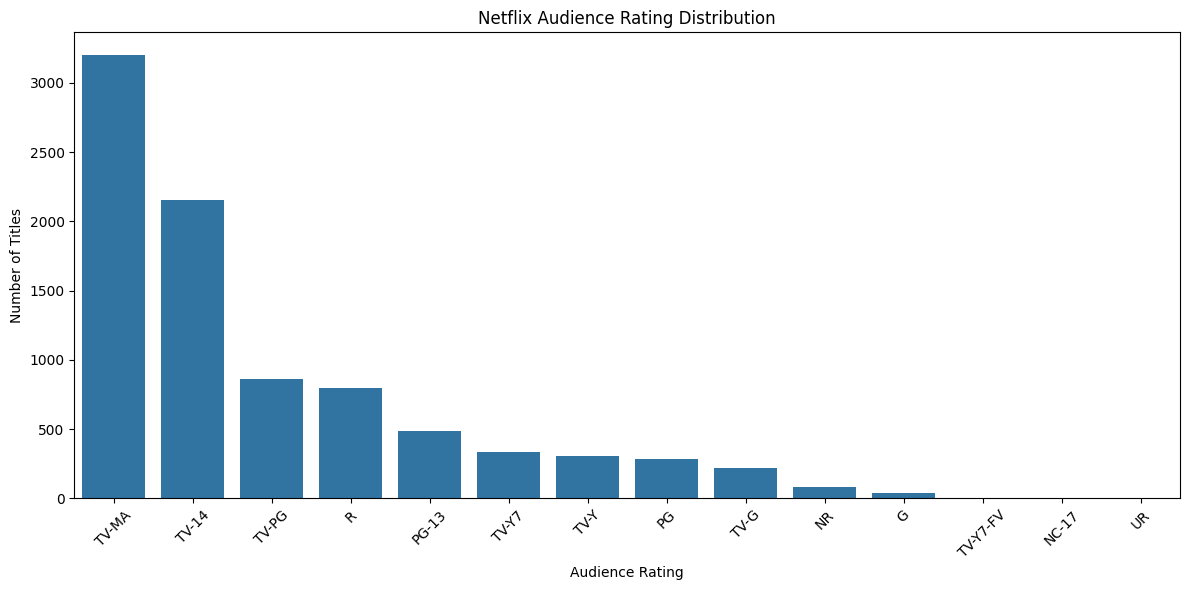

In [3]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x='rating',
    order=df['rating'].value_counts().index
)

plt.title('Netflix Audience Rating Distribution')
plt.xlabel('Audience Rating')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig('rating_distribution.png', dpi=300)
plt.show()

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Select features
features = ['type', 'release_year', 'country', 'listed_in', 'duration']

X = df[features].copy()
y = df['rating'].copy()

# Handle missing values
X = X.fillna('Unknown')
y = y.fillna('Unknown')

# Encode target labels
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)
print("Number of Rating Classes:", len(label_encoder.classes_))
print("\nRating Classes:")
print(label_encoder.classes_)

display(X.head())

Features Shape: (8790, 5)
Target Shape: (8790,)
Number of Rating Classes: 14

Rating Classes:
['G' 'NC-17' 'NR' 'PG' 'PG-13' 'R' 'TV-14' 'TV-G' 'TV-MA' 'TV-PG' 'TV-Y'
 'TV-Y7' 'TV-Y7-FV' 'UR']


,type,release_year,country,listed_in,duration
0,Movie,2020,United States,Documentaries,90 min
1,TV Show,2021,France,"Crime TV Shows, International TV Shows, TV Act...",1 Season
2,TV Show,2021,United States,"TV Dramas, TV Horror, TV Mysteries",1 Season
3,Movie,2021,Brazil,"Children & Family Movies, Comedies",91 min
4,Movie,1993,United States,"Dramas, Independent Movies, International Movies",125 min


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Data: (7032, 5)
Testing Data: (1758, 5)
Training Target: (7032,)
Testing Target: (1758,)


In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

numeric_features = ['release_year']
categorical_features = ['type', 'country', 'listed_in', 'duration']

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
])

rating_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=150,
        random_state=42,
        class_weight='balanced'
    ))
])

rating_model.fit(X_train, y_train)

print("Random Forest Model Training Completed!")

Random Forest Model Training Completed!


In [7]:
from sklearn.metrics import (
    accuracy_score,
    classification_report
)

# Predict ratings
y_pred = rating_model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

# Detailed classification report
print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    labels=range(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

Model Accuracy: 50.8 %

Classification Report:

              precision    recall  f1-score   support

           G       1.00      0.62      0.77         8
       NC-17       0.00      0.00      0.00         1
          NR       0.00      0.00      0.00        16
          PG       0.58      0.44      0.50        57
       PG-13       0.47      0.40      0.43        98
           R       0.53      0.51      0.52       160
       TV-14       0.49      0.46      0.47       431
        TV-G       0.11      0.07      0.08        44
       TV-MA       0.57      0.71      0.63       641
       TV-PG       0.24      0.16      0.19       172
        TV-Y       0.51      0.49      0.50        61
       TV-Y7       0.48      0.43      0.45        67
    TV-Y7-FV       0.00      0.00      0.00         1
          UR       0.00      0.00      0.00         1

    accuracy                           0.51      1758
   macro avg       0.35      0.31      0.33      1758
weighted avg       0.49      0.5

<Figure size 1200x1000 with 0 Axes>

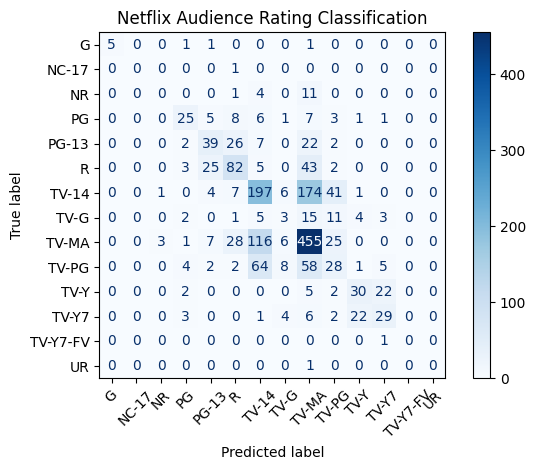

In [8]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=range(len(label_encoder.classes_))
)

plt.figure(figsize=(12, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

disp.plot(cmap='Blues', xticks_rotation=45, values_format='d')

plt.title('Netflix Audience Rating Classification')
plt.tight_layout()

plt.savefig('rating_confusion_matrix.png', dpi=300)
plt.show()

In [9]:
from sklearn.linear_model import LogisticRegression

lr_rating_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=2000,
        class_weight='balanced'
    ))
])

lr_rating_model.fit(X_train, y_train)

lr_predictions = lr_rating_model.predict(X_test)

lr_accuracy = accuracy_score(y_test, lr_predictions)

print("Random Forest Accuracy:", round(accuracy * 100, 2), "%")
print("Logistic Regression Accuracy:", round(lr_accuracy * 100, 2), "%")

Random Forest Accuracy: 50.8 %
Logistic Regression Accuracy: 44.37 %


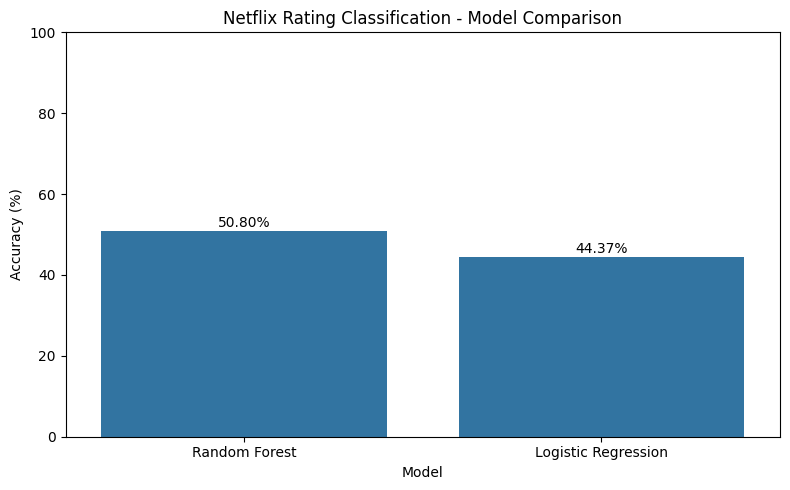

In [10]:
results = pd.DataFrame({
    'Model': ['Random Forest', 'Logistic Regression'],
    'Accuracy': [accuracy * 100, lr_accuracy * 100]
})

plt.figure(figsize=(8, 5))

sns.barplot(data=results, x='Model', y='Accuracy')

plt.title('Netflix Rating Classification - Model Comparison')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 100)

for i, value in enumerate(results['Accuracy']):
    plt.text(i, value + 1, f'{value:.2f}%', ha='center')

plt.tight_layout()
plt.savefig('rating_model_comparison.png', dpi=300)
plt.show()

In [11]:
new_content = pd.DataFrame({
    'type': ['Movie'],
    'release_year': [2022],
    'country': ['United States'],
    'listed_in': ['Dramas, International Movies'],
    'duration': ['120 min']
})

prediction = rating_model.predict(new_content)

predicted_rating = label_encoder.inverse_transform(prediction)

print("Predicted Audience Rating:", predicted_rating[0])

Predicted Audience Rating: TV-MA


In [12]:
import joblib

joblib.dump(rating_model, 'netflix_rating_model.pkl')
joblib.dump(label_encoder, 'rating_label_encoder.pkl')

print("Model saved successfully!")

Model saved successfully!


# Task 3: Netflix Audience Rating Classification

## 1. Project Overview

This project uses Machine Learning classification algorithms to predict audience ratings for Netflix content based on content-related features.

## 2. Dataset

* Dataset: Netflix Titles Dataset
* Total Records: 8,790
* Total Features: 10
* Target Variable: Rating
* Rating Categories: 14

## 3. Technologies Used

* Python
* Pandas
* NumPy
* Matplotlib
* Seaborn
* Scikit-learn
* Joblib
* Google Colab

## 4. Data Preprocessing

* Loaded and explored the dataset.
* Selected relevant input features.
* Handled missing values.
* Encoded audience rating labels.
* Split data into 80% training and 20% testing sets.

## 5. Machine Learning Models

Two classification models were implemented:

* Random Forest Classifier
* Logistic Regression

## 6. Model Evaluation

| Model               | Accuracy |
| ------------------- | -------: |
| Random Forest       |   50.80% |
| Logistic Regression |   44.37% |

Random Forest achieved better accuracy and was selected as the final model.

## 7. Prediction Testing

The trained model was tested using a new Netflix content sample. Its predicted audience rating was TV-MA.

## 8. Model Saving

The trained Random Forest model and rating label encoder were saved using Joblib for future use.

## 9. Conclusion

This project demonstrates the application of supervised machine learning classification techniques for predicting Netflix audience ratings. Random Forest performed better than Logistic Regression on the test dataset.
